# Exploratory Data Analysis

## Library Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus
from pathlib import Path

## Load Data & Build MySQL Database

In [2]:
# load to dataframes
invoices = pd.read_pickle("../Data/Cleaned/invoices_cleaned.pkl")
invoice_charges = pd.read_pickle('../Data/Cleaned/invoice_charges_cleaned.pkl')
payments = pd.read_pickle('../Data/Cleaned/payments_cleaned.pkl')
projects = pd.read_pickle('../Data/Cleaned/projects_cleaned.pkl')
vendors = pd.read_pickle('../Data/Cleaned/vendors_cleaned.pkl')

# note: pickle files were excluded from repository. Run 'data_cleaning.ipynb' to create pickle files.

In [3]:
# connect to MySQL
load_dotenv(dotenv_path=Path("../.env"))

user = os.getenv("MYSQL_USER")
password = quote_plus(os.getenv("MYSQL_PASSWORD"))
host = os.getenv("MYSQL_HOST")
port = os.getenv("MYSQL_PORT")
database = os.getenv("MYSQL_DATABASE")

In [4]:
# connect to MySQL
engine = create_engine(
    f"mysql+pymysql://{user}:{password}@{host}:{port}"
)

# create database and reconnect
with engine.connect() as conn:
    conn.execute(text(f"CREATE DATABASE IF NOT EXISTS {database}"))

engine = create_engine(
    f"mysql+pymysql://{user}:{password}@{host}:{port}/{database}"
)

# test the connection
query = """
SELECT DATABASE();
"""

pd.read_sql_query(query, engine)

,DATABASE()
0,ap_project


In [5]:
# load dataframes into MySQL
vendors.to_sql("vendors", engine, if_exists="replace", index=False)
projects.to_sql("projects", engine, if_exists="replace", index=False)
invoices.to_sql("invoices", engine, if_exists="replace", index=False)
payments.to_sql("payments", engine, if_exists="replace", index=False)
invoice_charges.to_sql("invoice_charges", engine, if_exists="replace", index=False)

# confirm tables loaded
query = """
SHOW TABLES;
"""

pd.read_sql_query(query, engine)

,Tables_in_ap_project
0,invoice_charges
1,invoices
2,payments
3,projects
4,vendors
5,vw_ap_spend_detail
6,vw_ap_spend_overview
7,vw_paid_unpaid_summary


In [6]:
# check row counts
query = """
SELECT 'vendors' AS table_name, COUNT(*) AS row_count FROM vendors
UNION ALL
SELECT 'projects', COUNT(*) FROM projects
UNION ALL
SELECT 'invoices', COUNT(*) FROM invoices
UNION ALL
SELECT 'payments', COUNT(*) FROM payments
UNION ALL
SELECT 'invoice_charges', COUNT(*) FROM invoice_charges;
"""

row_counts = pd.read_sql_query(query, engine)
row_counts

,table_name,row_count
0,vendors,100
1,projects,50
2,invoices,1000
3,payments,877
4,invoice_charges,2510


In [7]:
# Preview one joined table to confirm relationships are working
query = """
SELECT
    i.invoice_id,
    i.invoice_number,
    v.vendor_name,
    v.vendor_type,
    i.invoice_date,
    i.due_date,
    p.payment_date,
    i.invoice_amount
FROM invoices i
LEFT JOIN payments p
    ON i.invoice_id = p.invoice_id
JOIN vendors v
    ON i.vendor_id = v.vendor_id
LIMIT 10;
"""

pd.read_sql_query(query, engine)

,invoice_id,invoice_number,vendor_name,vendor_type,invoice_date,due_date,payment_date,invoice_amount
0,INV000001,50188-430,RB Mac Construction Co Inc,Vendor,2025-12-29,2026-02-12,NaT,58912.34
1,INV000002,30728-872,Posylio GC Corp,Vendor,2025-01-25,2025-03-11,2025-02-20,62327.30
2,INV000003,94834-463,OP-Tech Environmental Services Inc,Subconsultant,2023-11-14,2024-01-13,2023-12-03,56412.67
3,INV000004,62470-544,Bison Elevator Service Inc,Vendor,2024-06-06,2024-08-05,2024-08-09,2152.84
4,INV000004,62470-544,Bison Elevator Service Inc,Vendor,2024-06-06,2024-08-05,2024-06-20,2152.84
5,INV000005,83954-320,American Jail Products LLC,Vendor,2024-03-23,2024-04-22,NaT,33368.21
6,INV000006,31315-683,Raw Power Electric Corp,Vendor,2025-12-01,2026-01-15,NaT,62620.46
7,INV000007,93581-560,Empire Mechanical Services Inc,Vendor,2025-01-05,2025-02-19,2025-02-05,15310.38
8,INV000008,55486-171,Premier Mechanical Services Incorporated,Vendor,2024-04-27,2024-06-11,2024-07-01,77470.43
9,INV000008,55486-171,Premier Mechanical Services Incorporated,Vendor,2024-04-27,2024-06-11,2024-05-12,77470.43


## Data Analysis and Visualizations

###### Notes: 
* find vendors whose payment terms don't match invoice due dates
* show versions where invoices that show as unpaid are dropped, because this dataset is likely outdated and only captures a moment in time - not a live dataset
* us paying them late shouldn't be the main focus of the analysis. What about project payments, how much each project costs, most costly charges, etc?
* can probably remove subconsultants

1. AP Spend Overview
2. Vendor Spend Analysis
3. Project Cost Analysis
4. Invoice Charge Breakdown
5. Payment Performance
6. Cash Flow Trends

### 1. AP Spend Overview

#### Overall AP spend summary

In [8]:
query = """
WITH payment_totals AS (
    SELECT
        invoice_id,
        SUM(payment_amount) AS total_paid_amount
    FROM payments
    GROUP BY invoice_id
),

invoice_summary AS (
    SELECT
        COUNT(DISTINCT i.invoice_id) AS total_invoices,
        COUNT(DISTINCT i.vendor_id) AS vendors_involved,
        ROUND(SUM(i.invoice_amount), 2) AS total_invoice_spend,
        ROUND(SUM(COALESCE(pt.total_paid_amount, 0)), 2) AS total_paid_amount,
        ROUND(
            SUM(i.invoice_amount) - SUM(COALESCE(pt.total_paid_amount, 0)),
            2
        ) AS total_unpaid_amount,
        ROUND(
            100.0 * SUM(COALESCE(pt.total_paid_amount, 0)) / SUM(i.invoice_amount),
            1
        ) AS percent_paid
    FROM invoices i
    LEFT JOIN payment_totals pt
        ON i.invoice_id = pt.invoice_id
),

project_summary AS (
    SELECT
        COUNT(DISTINCT project_id) AS total_projects
    FROM projects
),

ap_project_summary AS (
    SELECT
        COUNT(DISTINCT project_id) AS projects_with_ap_charges
    FROM invoice_charges
)

SELECT
    invoice_summary.total_invoices,
    invoice_summary.vendors_involved,
    project_summary.total_projects,
    ap_project_summary.projects_with_ap_charges,
    invoice_summary.total_invoice_spend,
    invoice_summary.total_paid_amount,
    invoice_summary.total_unpaid_amount,
    invoice_summary.percent_paid

FROM invoice_summary
CROSS JOIN project_summary
CROSS JOIN ap_project_summary;
"""

ap_spend_overview = pd.read_sql_query(query, engine)
ap_spend_overview

,total_invoices,vendors_involved,total_projects,projects_with_ap_charges,total_invoice_spend,total_paid_amount,total_unpaid_amount,percent_paid
0,1000,100,50,50,41536472.74,30064297.47,11472175.27,72.4


In [20]:
# create SQL view for PowerBI
query = """
CREATE OR REPLACE VIEW vw_ap_spend_detail AS

WITH payment_totals AS (
    SELECT
        invoice_id,
        SUM(payment_amount) AS total_paid_amount,
        MAX(payment_date) AS latest_payment_date
    FROM payments
    GROUP BY invoice_id
)

SELECT
    i.invoice_id,
    i.invoice_number,
    DATE(i.invoice_date) AS invoice_date,
    DATE(i.due_date) AS due_date,
    i.invoice_amount,

    v.vendor_id,
    v.vendor_name,
    v.vendor_type,
    v.payment_terms,

    DATEDIFF(i.due_date, i.invoice_date) AS vendor_terms_from_invoice,

    DATE(pt.latest_payment_date) AS latest_payment_date,

    COALESCE(pt.total_paid_amount, 0) AS total_paid_amount,

    GREATEST(
        i.invoice_amount - COALESCE(pt.total_paid_amount, 0),
        0
    ) AS remaining_balance,

    CASE
        WHEN COALESCE(pt.total_paid_amount, 0) >= i.invoice_amount
        THEN 'Paid'

        WHEN COALESCE(pt.total_paid_amount, 0) > 0
        THEN 'Partially Paid'

        ELSE 'Unpaid'
    END AS payment_status

FROM invoices i
JOIN vendors v
    ON i.vendor_id = v.vendor_id
LEFT JOIN payment_totals pt
    ON i.invoice_id = pt.invoice_id;
"""

with engine.connect() as conn:
    conn.execute(text(query))

In [21]:
# preview view
query = """
SELECT *
FROM vw_ap_spend_detail
ORDER BY invoice_date ASC;
"""

ap_spend_detail = pd.read_sql_query(query, engine)

ap_spend_detail.head()

,invoice_id,invoice_number,invoice_date,due_date,invoice_amount,vendor_id,vendor_name,vendor_type,payment_terms,vendor_terms_from_invoice,latest_payment_date,total_paid_amount,remaining_balance,payment_status
0,INV000938,78183-698,2023-01-01,2023-01-31,65366.14,V0082,Premier Mechanical Services Incorporated,Vendor,Net 30,30,2023-01-18,65366.14,0.000000e+00,Paid
1,INV000504,98381-566,2023-01-03,2023-02-02,30292.46,V0073,Orchard Earth & Pipe Corp,Vendor,Net 30,30,2023-01-21,30292.46,0.000000e+00,Paid
2,INV000551,75669-362,2023-01-03,2023-02-02,18612.23,V0010,Aecom Technical Services Northeast Inc,Subconsultant,Net 30,30,2023-01-21,18612.23,0.000000e+00,Paid
3,INV000488,37818-559,2023-01-04,2023-02-18,39832.73,V0090,RB Robinson Contracting Inc,Vendor,Net 60,45,2023-01-31,39832.73,0.000000e+00,Paid
4,INV000132,72225-876,2023-01-05,2023-02-04,31267.56,V0051,Dakota Environmental Services LLC,Subconsultant,Net 60,30,2023-03-11,31267.56,3.637979e-12,Partially Paid


#### Paid vs. unpaid invoice summary

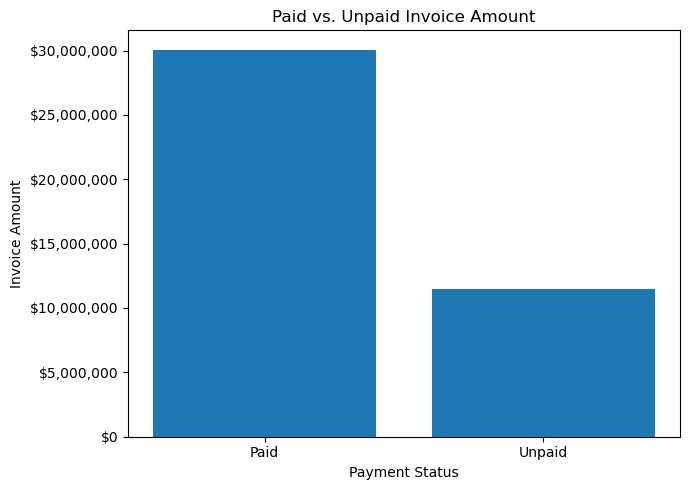

In [11]:
paid_unpaid = ap_spend_overview[[
    "total_paid_amount",
    "total_unpaid_amount"
]].T.reset_index()

paid_unpaid.columns = ["payment_status", "amount"]

paid_unpaid["payment_status"] = paid_unpaid["payment_status"].replace({
    "total_paid_amount": "Paid",
    "total_unpaid_amount": "Unpaid"
})

plt.figure(figsize=(7, 5))

plt.bar(
    paid_unpaid["payment_status"],
    paid_unpaid["amount"]
)

plt.title("Paid vs. Unpaid Invoice Amount")
plt.xlabel("Payment Status")
plt.ylabel("Invoice Amount")

plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

plt.tight_layout()
plt.show()

#### Total invoice spend and invoice count by vendor type

In [12]:
query = """
SELECT
    v.vendor_type,

    COUNT(DISTINCT i.invoice_id) AS invoice_count,

    COUNT(DISTINCT v.vendor_id) AS vendor_count,

    ROUND(SUM(i.invoice_amount), 2) AS total_invoice_spend,

    ROUND(AVG(i.invoice_amount), 2) AS avg_invoice_amount

FROM invoices i
JOIN vendors v
    ON i.vendor_id = v.vendor_id

GROUP BY v.vendor_type
ORDER BY total_invoice_spend DESC;
"""

spend_by_vendor_type = pd.read_sql_query(query, engine)
spend_by_vendor_type

,vendor_type,invoice_count,vendor_count,total_invoice_spend,avg_invoice_amount
0,Vendor,814,82,33551268.60,41217.77
1,Subconsultant,186,18,7985204.14,42931.21


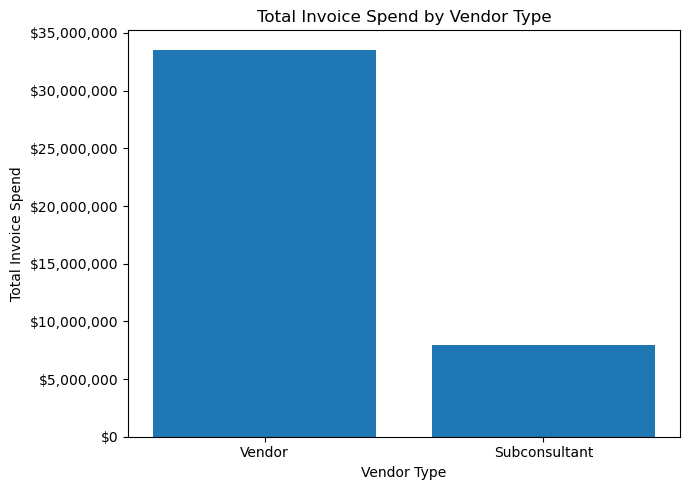

In [13]:
plt.figure(figsize=(7, 5))

plt.bar(
    spend_by_vendor_type["vendor_type"],
    spend_by_vendor_type["total_invoice_spend"]
)

plt.title("Total Invoice Spend by Vendor Type")
plt.xlabel("Vendor Type")
plt.ylabel("Total Invoice Spend")

plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

plt.tight_layout()
plt.show()

### 2. Vendor Spend Analysis

In [14]:
# Top vendors by total invoice amount
query = """
SELECT
    v.vendor_id,
    v.vendor_name,
    COUNT(i.invoice_id) AS invoice_count,
    ROUND(SUM(i.invoice_amount), 2) AS total_invoice_amount,
    ROUND(AVG(i.invoice_amount), 2) AS avg_invoice_amount
FROM invoices i
JOIN vendors v
    ON i.vendor_id = v.vendor_id
GROUP BY
    v.vendor_id,
    v.vendor_name
ORDER BY total_invoice_amount DESC;
"""

vendor_spend = pd.read_sql_query(query, engine)

vendor_spend

,vendor_id,vendor_name,invoice_count,total_invoice_amount,avg_invoice_amount
0,V0072,OP-Tech Environmental Services Inc,16,817995.09,51124.69
1,V0085,Ran Fire Protection Engineering PC,18,816134.41,45340.80
2,V0021,American Pump & Tank Installation Co Inc,16,733088.12,45818.01
3,V0095,Reliant Electrical Contracting Inc,17,704063.22,41415.48
4,V0025,Anjac Enterprises Inc,15,696306.19,46420.41
...,...,...,...,...,...
95,V0028,Bayside Refrigeration Inc,4,163374.46,40843.62
96,V0033,Black Horse Group LLC,5,147158.97,29431.79
97,V0006,A Peter Luger Construction Inc,6,133806.52,22301.09
98,V0066,New Century Electric Inc,5,77526.59,15505.32


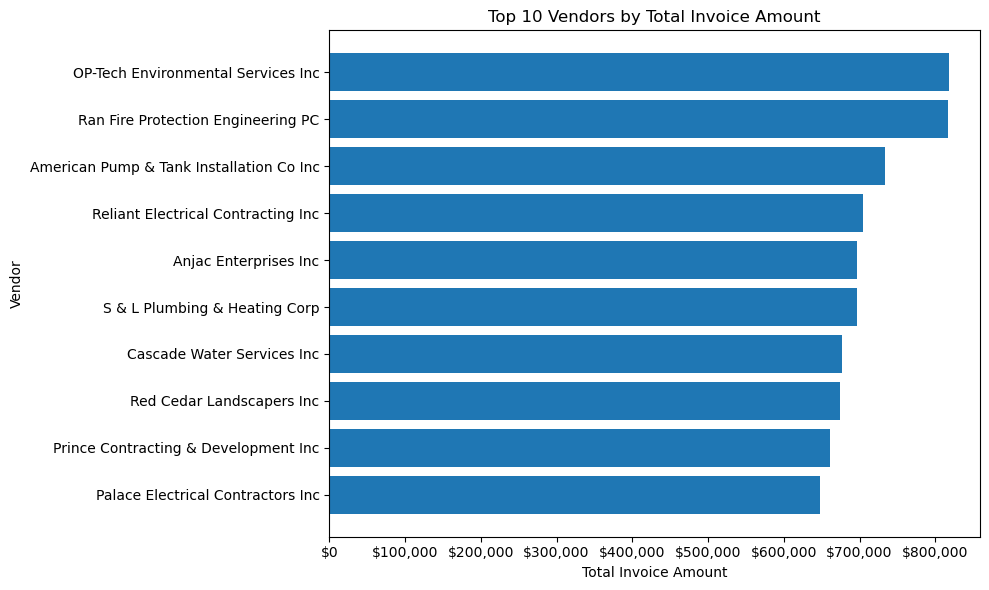

In [15]:
# Horizontal bar chart: Top 10 vendors by spend

top_10_vendor_spend = vendor_spend.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_vendor_spend["vendor_name"],
    top_10_vendor_spend["total_invoice_amount"]
)

plt.title("Top 10 Vendors by Total Invoice Amount")
plt.xlabel("Total Invoice Amount")
plt.ylabel("Vendor")

plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [16]:
# Invoice count by vendor
query = """
SELECT
    v.vendor_id,
    v.vendor_name,
    COUNT(i.invoice_id) AS invoice_count
FROM invoices i
JOIN vendors v
    ON i.vendor_id = v.vendor_id
GROUP BY
    v.vendor_id,
    v.vendor_name
ORDER BY invoice_count DESC;
"""

invoice_count_by_vendor = pd.read_sql_query(query, engine)

invoice_count_by_vendor

,vendor_id,vendor_name,invoice_count
0,V0087,Ray S Pantel Inc,19
1,V0085,Ran Fire Protection Engineering PC,18
2,V0095,Reliant Electrical Contracting Inc,17
3,V0072,OP-Tech Environmental Services Inc,16
4,V0019,American Jail Products LLC,16
...,...,...,...
95,V0066,New Century Electric Inc,5
96,V0033,Black Horse Group LLC,5
97,V0024,Andron Construction Corp,4
98,V0028,Bayside Refrigeration Inc,4


In [17]:
# average invoice amount by vendor
query = """
SELECT
    v.vendor_id,
    v.vendor_name,
    ROUND(AVG(i.invoice_amount), 2) AS avg_invoice_amount
FROM invoices i
JOIN vendors v
    ON i.vendor_id = v.vendor_id
GROUP BY
    v.vendor_id,
    v.vendor_name
ORDER BY avg_invoice_amount DESC;
"""

avg_invoice_amount = pd.read_sql_query(query, engine)

avg_invoice_amount

,vendor_id,vendor_name,avg_invoice_amount
0,V0069,OCS Industries,74495.28
1,V0013,Ajay Glass & Mirror Co Inc,60879.23
2,V0038,C&S Technical Resources Inc,57400.99
3,V0097,RSI Roofing Inc,56867.12
4,V0048,Crisafulli Brothers Plumbing & Heating,56573.83
...,...,...,...
95,V0029,BBL Construction Services LLC,27623.53
96,V0002,192 Branch Interior Services Inc,27270.59
97,V0006,A Peter Luger Construction Inc,22301.09
98,V0066,New Century Electric Inc,15505.32


In [18]:
# Identify vendor spend outliers with the IQR method
Q1 = vendor_spend["total_invoice_amount"].quantile(0.25)
Q3 = vendor_spend["total_invoice_amount"].quantile(0.75)

# calculate the interquantile range - the spread of the middle 50% of vendor spend values
IQR = Q3 - Q1
upper_limit = Q3 + (1.5 * IQR)

vendor_spend_outliers = vendor_spend[
    vendor_spend["total_invoice_amount"] > upper_limit
].sort_values("total_invoice_amount", ascending=False)

vendor_spend_outliers

,vendor_id,vendor_name,invoice_count,total_invoice_amount,avg_invoice_amount
0,V0072,OP-Tech Environmental Services Inc,16,817995.09,51124.69
1,V0085,Ran Fire Protection Engineering PC,18,816134.41,45340.80


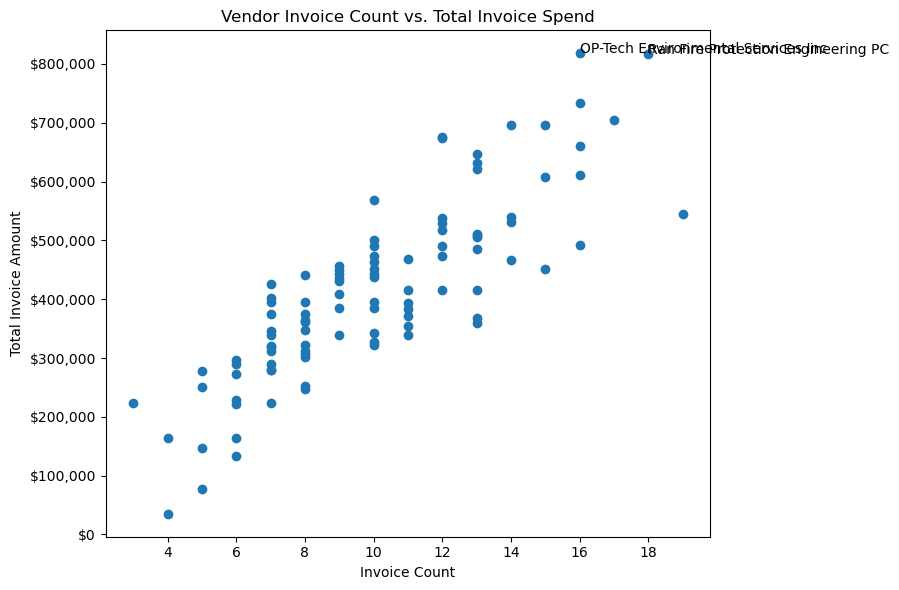

In [19]:
# scatter plot to explore why a vendor has high spend
plt.figure(figsize=(9, 6))

plt.scatter(
    vendor_spend["invoice_count"],
    vendor_spend["total_invoice_amount"]
)

plt.title("Vendor Invoice Count vs. Total Invoice Spend")
plt.xlabel("Invoice Count")
plt.ylabel("Total Invoice Amount")

plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

for _, row in vendor_spend_outliers.iterrows():
    plt.annotate(
        row["vendor_name"],
        (row["invoice_count"], row["total_invoice_amount"])
    )

plt.tight_layout()
plt.show()

In [22]:
# create SQL view for PowerBI
query = """
CREATE OR REPLACE VIEW vw_vendor_detail AS

WITH payment_totals AS (
    SELECT
        invoice_id,
        SUM(payment_amount) AS total_paid_amount,
        MAX(payment_date) AS latest_payment_date
    FROM payments
    GROUP BY invoice_id
)

SELECT
    i.invoice_id,
    i.invoice_number,
    DATE(i.invoice_date) AS invoice_date,
    DATE(i.due_date) AS due_date,
    i.invoice_amount,

    v.vendor_id,
    v.vendor_name,
    v.vendor_type,
    v.payment_terms,

    CASE
        WHEN v.payment_terms = 'Net 15' THEN 15
        WHEN v.payment_terms = 'Net 30' THEN 30
        WHEN v.payment_terms = 'Net 45' THEN 45
        WHEN v.payment_terms = 'Net 60' THEN 60
        ELSE NULL
    END AS payment_terms_days,

    DATEDIFF(i.due_date, i.invoice_date) AS vendor_terms_from_invoice,

    DATE(pt.latest_payment_date) AS latest_payment_date,

    COALESCE(pt.total_paid_amount, 0) AS total_paid_amount,

    GREATEST(
        i.invoice_amount - COALESCE(pt.total_paid_amount, 0),
        0
    ) AS remaining_balance,

    CASE
        WHEN COALESCE(pt.total_paid_amount, 0) >= i.invoice_amount
        THEN 'Paid'

        WHEN COALESCE(pt.total_paid_amount, 0) > 0
        THEN 'Partially Paid'

        ELSE 'Unpaid'
    END AS payment_status

FROM invoices i
JOIN vendors v
    ON i.vendor_id = v.vendor_id
LEFT JOIN payment_totals pt
    ON i.invoice_id = pt.invoice_id;
"""

with engine.connect() as conn:
    conn.execute(text(query))

In [23]:
# preview view
query = """
SELECT *
FROM vw_vendor_detail
ORDER BY invoice_date ASC;
"""

vendor_detail = pd.read_sql_query(query, engine)

vendor_detail.head()

,invoice_id,invoice_number,invoice_date,due_date,invoice_amount,vendor_id,vendor_name,vendor_type,payment_terms,payment_terms_days,vendor_terms_from_invoice,latest_payment_date,total_paid_amount,remaining_balance,payment_status
0,INV000938,78183-698,2023-01-01,2023-01-31,65366.14,V0082,Premier Mechanical Services Incorporated,Vendor,Net 30,30,30,2023-01-18,65366.14,0.000000e+00,Paid
1,INV000504,98381-566,2023-01-03,2023-02-02,30292.46,V0073,Orchard Earth & Pipe Corp,Vendor,Net 30,30,30,2023-01-21,30292.46,0.000000e+00,Paid
2,INV000551,75669-362,2023-01-03,2023-02-02,18612.23,V0010,Aecom Technical Services Northeast Inc,Subconsultant,Net 30,30,30,2023-01-21,18612.23,0.000000e+00,Paid
3,INV000488,37818-559,2023-01-04,2023-02-18,39832.73,V0090,RB Robinson Contracting Inc,Vendor,Net 60,60,45,2023-01-31,39832.73,0.000000e+00,Paid
4,INV000132,72225-876,2023-01-05,2023-02-04,31267.56,V0051,Dakota Environmental Services LLC,Subconsultant,Net 60,60,30,2023-03-11,31267.56,3.637979e-12,Partially Paid


For PowerBI:
* top 10 of the above stats
* vendors with the most payments
* what outliers can be found in this dataset?

### 3. Project Cost Analysis

Which projects generate the highest vendor costs?

Are costs concentrated in a few projects?

Which project types drive the most AP spend?


Good queries/visuals:

Top 10 projects by total vendor cost

Spend by project type

Invoice count by project

Average charge amount by project

good chart:

Horizontal bar chart: Top 10 projects by vendor cost

### 4. Invoice Charge Breakdown

What charges exist within the costliest projects?

Which projects have many smaller charges vs. fewer large charges?

Which vendors contribute to the highest-cost projects?


Good queries/visuals:

Charge breakdown for top projects

Top charges by project

Vendor charges within each high-cost project

Charge count by project

Average charge amount by project

### 5. Payment Performance

For PowerBI:
* vendors who are paid late
* review payment terms compared to invoice dates: if payment terms don't match, advise team to review vendor contract to see what the correct payment terms are

How long does it take to pay invoices?

How often are invoices paid late?

Which vendors are most affected by late payments?

What dollar amount is associated with late payments?

queries/visuals:

Average days to pay

Late payment rate

Late paid invoice amount by vendor

Vendors never paid late

Average days late for late invoices only

good charts:

Top 10 vendors by late paid invoice amount

Late payment rate by vendor type

### 6. Cash Flow Trends

How much cash goes out each month?

Are AP payments stable or uneven?

Which months had the highest payment volume?

Are cash outflows driven more by vendors or subconsultants?


Good queries/visuals:

Monthly payment totals

Monthly invoice totals

Monthly payments by vendor type

Monthly payment count

Average monthly payment amount


Good chart:

Line chart: Monthly AP cash outflow